
Benchmark: AR, ARCH, GARCH, HAR, HARCJ, LHARCJ, Stochastic Volatility models/frameworks 

Against: CNN, Temporal CNN, LSTM, DeepAR, Time Series Dense Encoder

Other exogenous variables: BRENT, USD-Rupee, Interest Rates, STT/GST/Taxes, Gold, bond-yeild (india, us), VIX, 

Forecast Errors: MAPE, MSE, MAE

In [114]:
import pandas as pd 
import numpy as np

from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import TimeSeriesSplit

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss)


import seaborn as sns 
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates

%matplotlib inline 

In [92]:
df = pd.read_csv('data/processed_data.csv',index_col=False)
df.head()

,Datetime,Open,High,Low,Close,Volume,time,symbol,daily_ret,rv_5,...,squared_ret,negative_ret,positive_ret,rv_5_change,rv_5_pct_chg,rv_ratio_5_20,rv_20_std,high_low_range,overnight_gap,target_rv_5
0,2014-01-01,11417.60,11432.55,11361.00,11423.85,0.0,09:15:00,NIFTY_BANK,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.006267,NaN,0.027072
1,2014-01-02,11387.25,11578.90,11150.20,11164.35,0.0,09:15:00,NIFTY_BANK,-0.022978,NaN,...,0.000528,-0.022978,0.000000,NaN,NaN,NaN,NaN,0.037647,-0.003204,0.015743
2,2014-01-03,11125.65,11208.00,11052.60,11203.95,0.0,09:15:00,NIFTY_BANK,0.003541,NaN,...,0.000013,0.000000,0.003541,NaN,NaN,NaN,NaN,0.013968,-0.003466,0.021253
3,2014-01-06,11163.80,11167.30,10996.95,11051.40,0.0,09:15:00,NIFTY_BANK,-0.013709,NaN,...,0.000188,-0.013709,0.000000,NaN,NaN,NaN,NaN,0.015259,-0.003584,0.027919
4,2014-01-07,11124.75,11154.10,10892.15,11036.10,0.0,09:15:00,NIFTY_BANK,-0.001385,NaN,...,0.000002,-0.001385,0.000000,NaN,NaN,NaN,NaN,0.023547,0.006637,0.029706


### Stationarity and autocorrelation checks

In [41]:
print('Adfuller Stationarity Check')

cols = ['Close', 'daily_ret', 'rv_5', 'rv_10', 'rv_21', 
        'rv_63', 'annualized_rv', 'ret_lag_1', 'ret_lag_2', 
        'ret_lag_3', 'daily_abs', 'squared_ret', 'negative_ret', 
        'positive_ret', 'rv_5_change', 'rv_5_pct_chg', 'rv_ratio_5_21',
        'rv_volatility_21', 'high_low_range', 'overnight_gap', 'target_rv_5']

cols_test = ['daily_ret', 'rv_5', 'rv_10', 'rv_21', 
        'rv_63', 'annualized_rv', 'ret_lag_1', 'ret_lag_2', 
        'ret_lag_3', 'daily_abs', 'squared_ret', 'negative_ret', 
        'positive_ret', 'rv_5_change', 'rv_5_pct_chg', 'rv_ratio_5_21',
        'rv_volatility_21', 'high_low_range', 'overnight_gap', 'target_rv_5']

for i in cols_test: 
    
    clean_series = df[i].dropna()
    
    print(i)
    
    adf_result = adfuller(clean_series, result_object=False)
    
    print(f"ADF Statistic: {adf_result[0]}")
    print(f"p-value: {adf_result[1]}") 
    print(f"Critical Values: {adf_result[4]}")
    
    if adf_result[1] <= 0.05:
        print("Reject H0: The time series is stationary.")
    else:
        print("Fail to reject H0: The time series is non-stationary.")

    # plot_acf(clean_series)
    # plt.show()

    print('\n')

    

Adfuller Stationarity Check
daily_ret
ADF Statistic: -14.940640720830809
p-value: 1.3241968079694271e-27
Critical Values: {'1%': np.float64(-3.432427002601706), '5%': np.float64(-2.8624576920765237), '10%': np.float64(-2.5672585088743345)}
Reject H0: The time series is stationary.


rv_5
ADF Statistic: -6.049184713532491
p-value: 1.2898430371637205e-07
Critical Values: {'1%': np.float64(-3.432435614191757), '5%': np.float64(-2.862461495644756), '10%': np.float64(-2.5672605338292387)}
Reject H0: The time series is stationary.


rv_10
ADF Statistic: -6.264368755829704
p-value: 4.1485842597559835e-08
Critical Values: {'1%': np.float64(-3.432443626977095), '5%': np.float64(-2.8624650347229847), '10%': np.float64(-2.5672624179758317)}
Reject H0: The time series is stationary.


rv_21
ADF Statistic: -4.886151347940117
p-value: 3.7104857465537026e-05
Critical Values: {'1%': np.float64(-3.432450351481275), '5%': np.float64(-2.862468004787272), '10%': np.float64(-2.567263999190068)}
Reject H0: 

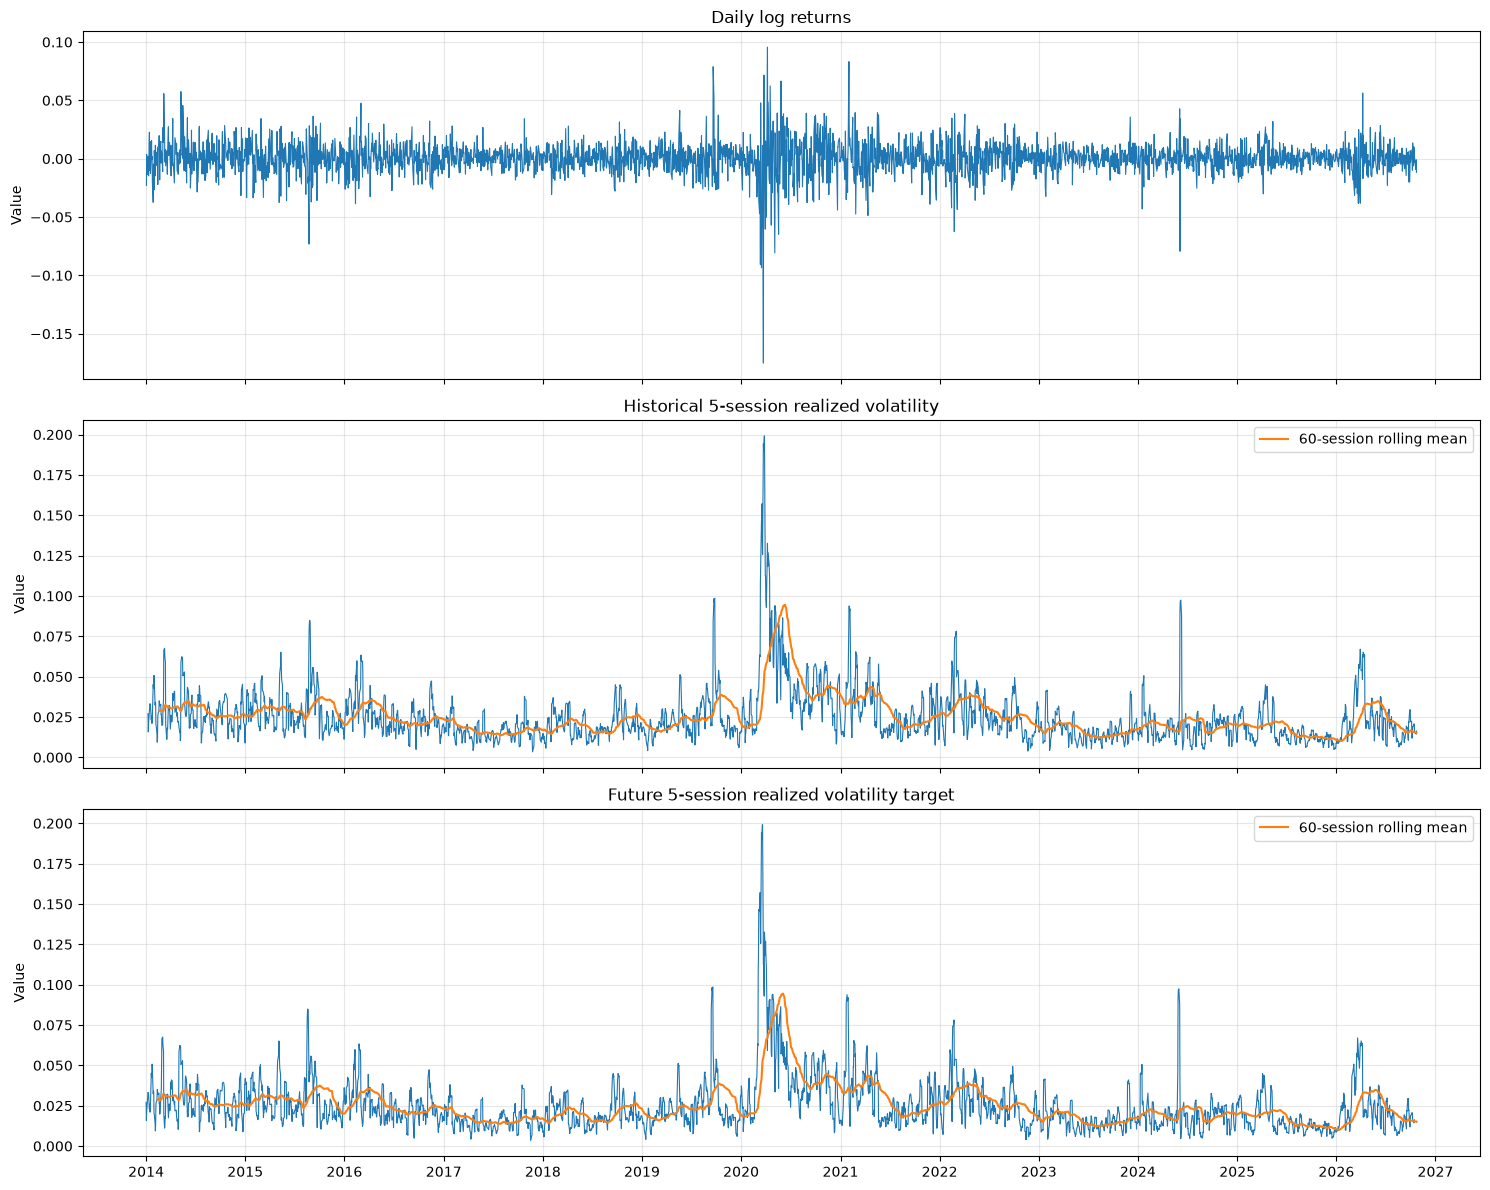

In [38]:
# df["Datetime"] = pd.to_datetime(df["Datetime"])
# df = df.sort_values("Datetime").set_index("Datetime")

plot_columns = [("daily_ret", "Daily log returns"),("rv_5", "Historical 5-session realized volatility"),("target_rv_5", "Future 5-session realized volatility target"),]

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

for ax, (column, title) in zip(axes, plot_columns):
    ax.plot(df.index, df[column], linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel("Value")
    ax.grid(True, alpha=0.3)

    if column != "daily_ret":
        rolling_mean = df[column].rolling(60, min_periods=30).mean()
        ax.plot(df.index,rolling_mean,linewidth=1.5,label="60-session rolling mean")
        ax.legend()

axes[-1].xaxis.set_major_locator(mdates.YearLocator(1))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig('hist_fut_rv_plots.png')
plt.show()

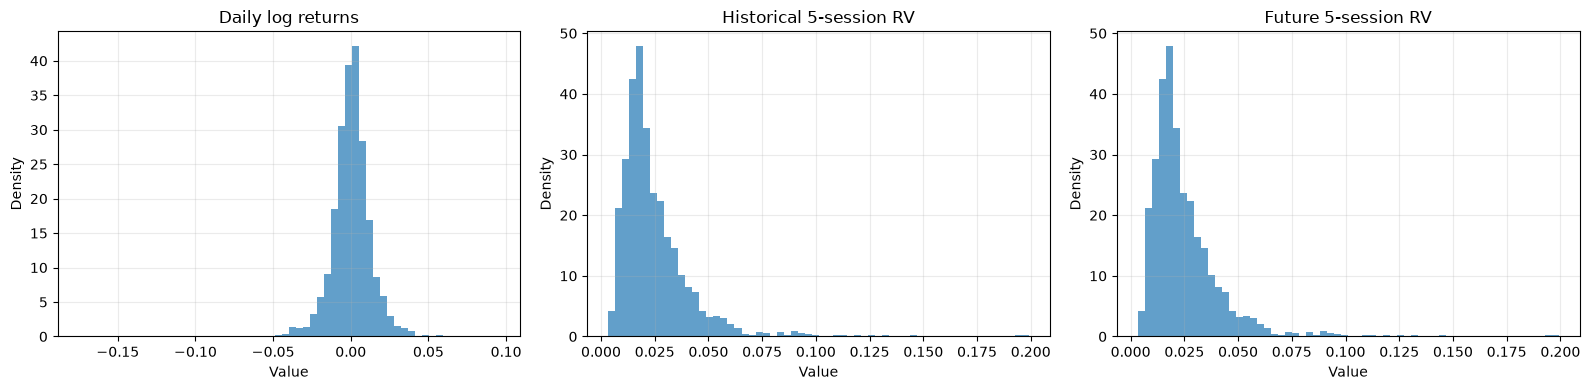

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

plot_variables = [
    ("daily_ret", "Daily log returns"),
    ("rv_5", "Historical 5-session RV"),
    ("target_rv_5", "Future 5-session RV"),
]

for ax, (column, title) in zip(axes, plot_variables):
    values = df[column].dropna()

    ax.hist(values, bins=60, density=True, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

In [44]:
df.columns

Index(['Open', 'High', 'Low', 'Close', 'Volume', 'time', 'symbol', 'daily_ret',
       'rv_5', 'rv_10', 'rv_21', 'rv_63', 'annualized_rv', 'ret_lag_1',
       'ret_lag_2', 'ret_lag_3', 'daily_abs', 'squared_ret', 'negative_ret',
       'positive_ret', 'rv_5_change', 'rv_5_pct_chg', 'rv_ratio_5_21',
       'rv_volatility_21', 'high_low_range', 'overnight_gap', 'target_rv_5'],
      dtype='str')

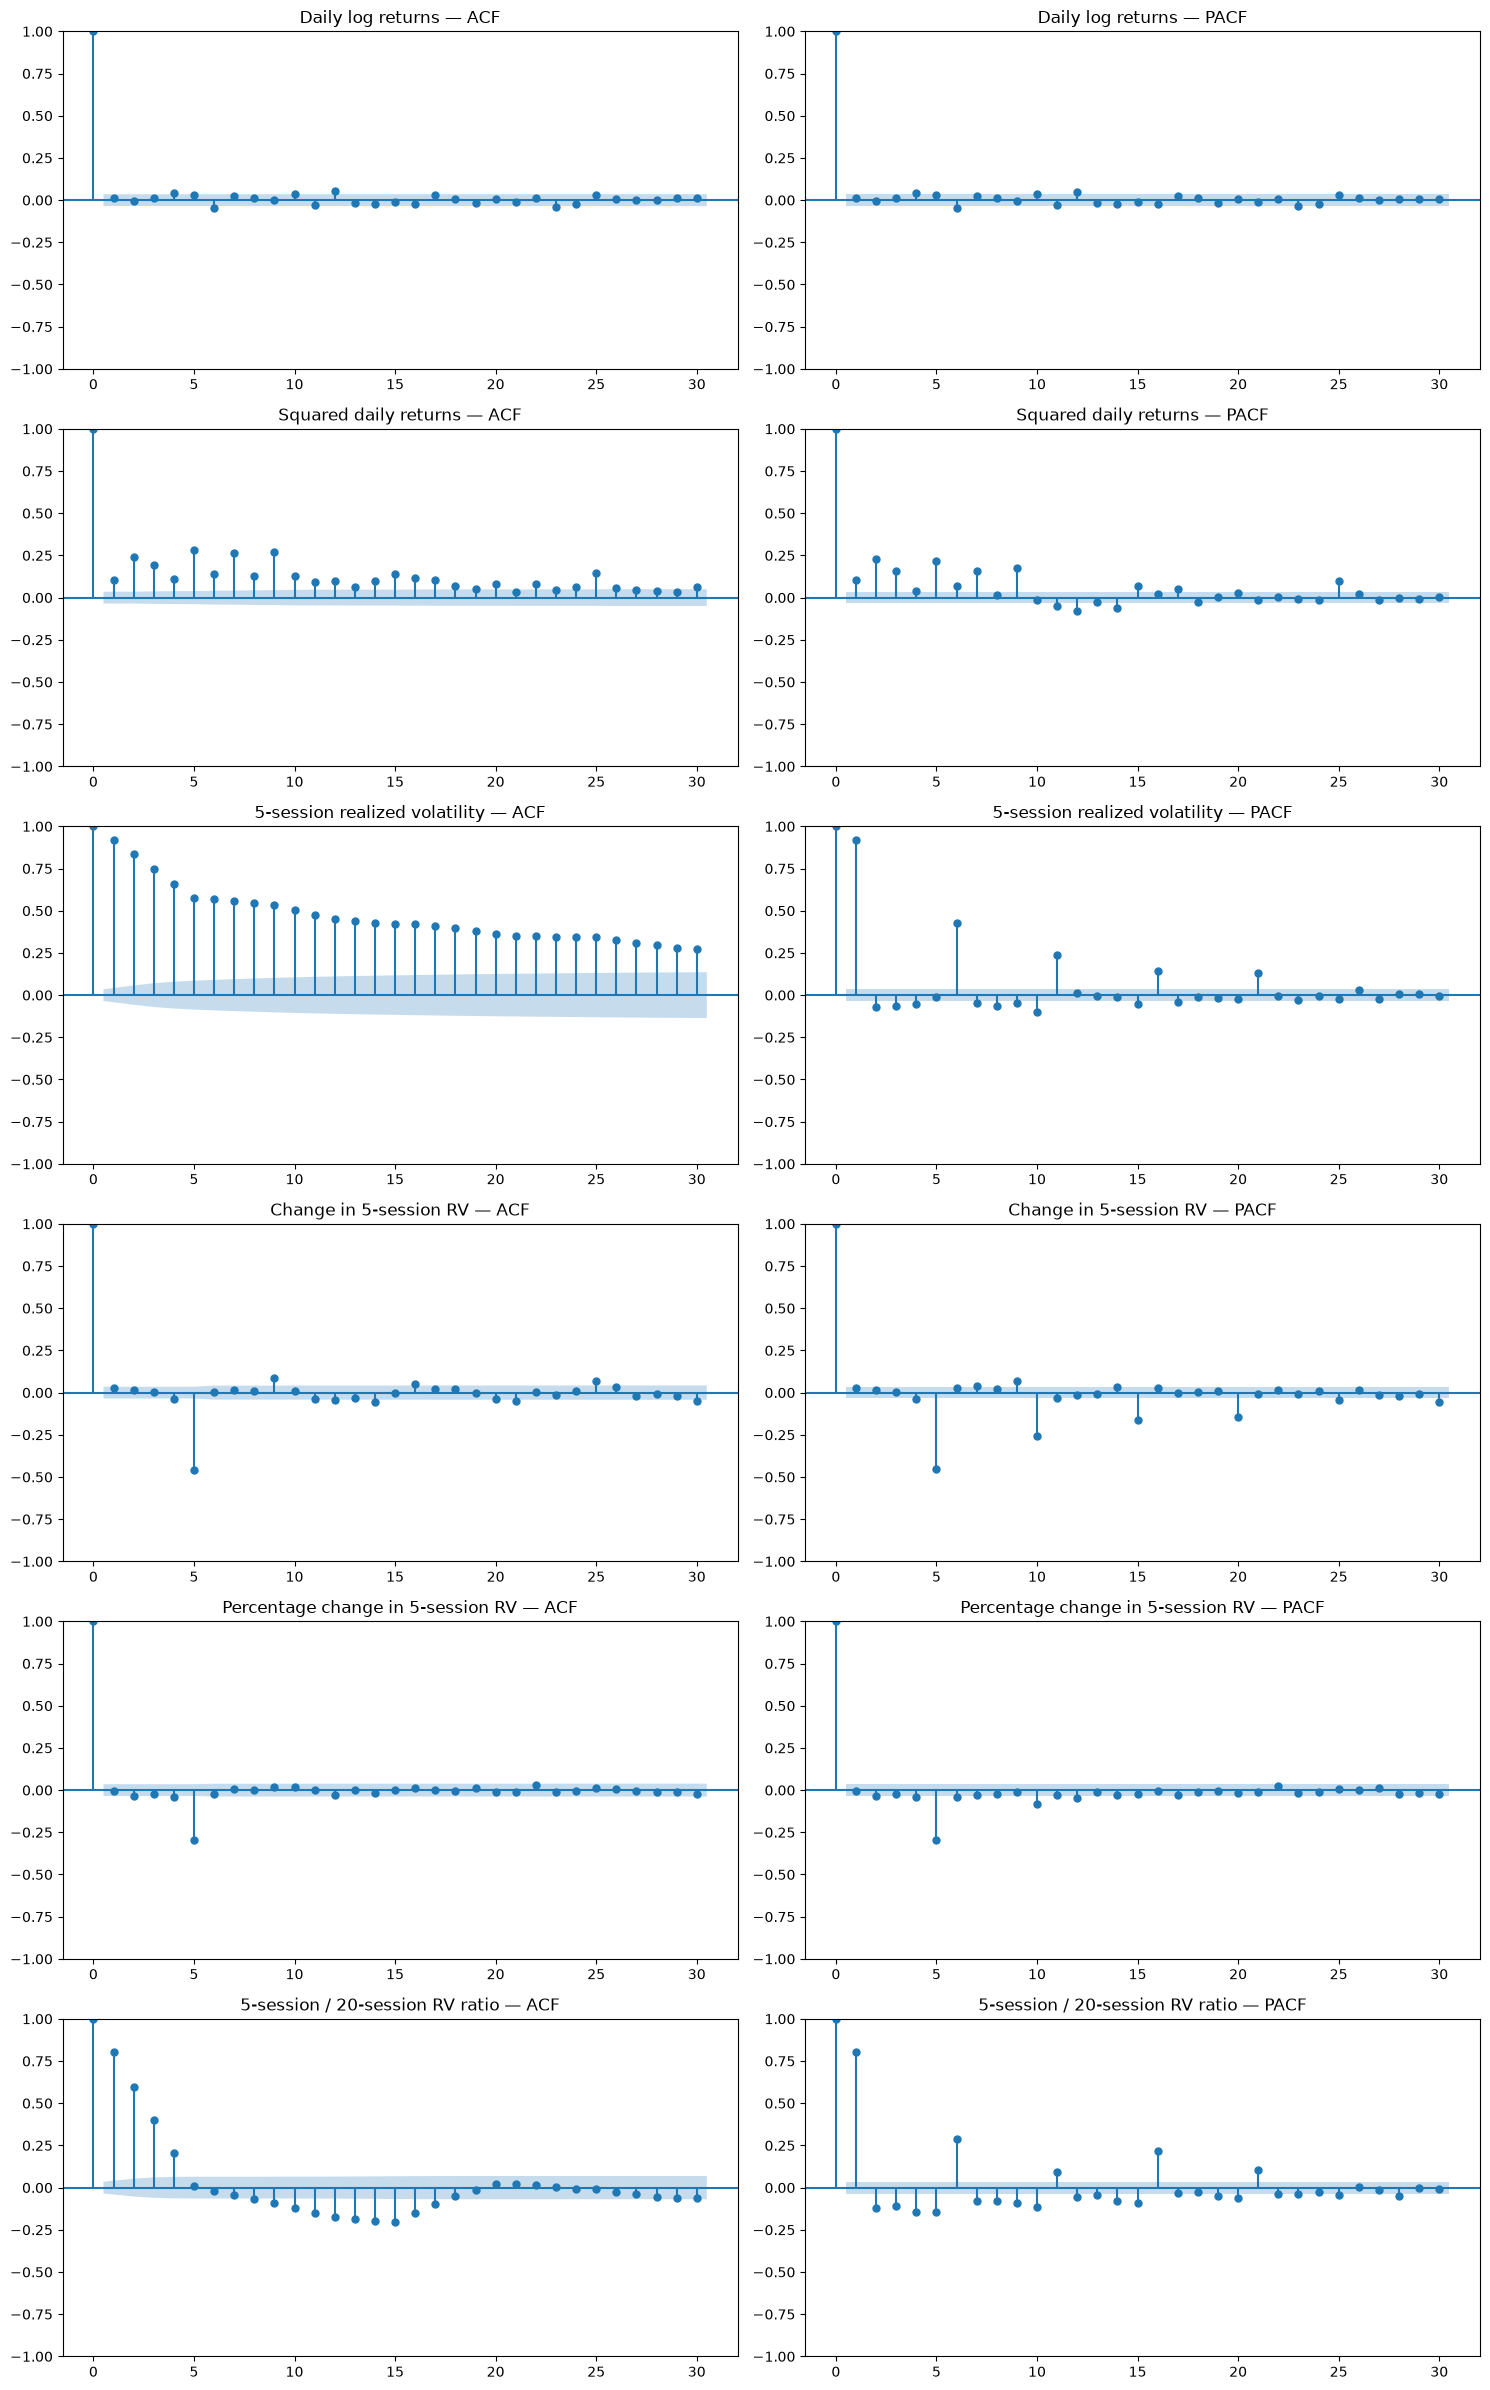

In [49]:
variables = [
    ("daily_ret", "Daily log returns"),
    ("squared_ret", "Squared daily returns"),
    ("rv_5", "5-session realized volatility"),
    ("rv_5_change", "Change in 5-session RV"),
    ("rv_5_pct_chg", "Percentage change in 5-session RV"),
    ("rv_ratio_5_20", "5-session / 20-session RV ratio"),]

fig, axes = plt.subplots(
    len(variables),
    2,
    figsize=(15, 4 * len(variables)))

for row, (column, title) in enumerate(variables):
    series = df[column].dropna()

    plot_acf(
        series,
        lags=30,
        ax=axes[row, 0],
        alpha=0.05,
        zero=True)
    axes[row, 0].set_title(f"{title} — ACF")

    plot_pacf(
        series,
        lags=30,
        ax=axes[row, 1],
        method="ywm",
        alpha=0.05,
        zero=True)
    
    axes[row, 1].set_title(f"{title} — PACF")

plt.tight_layout()
plt.savefig('acf_pacf_plots.png')
plt.show()

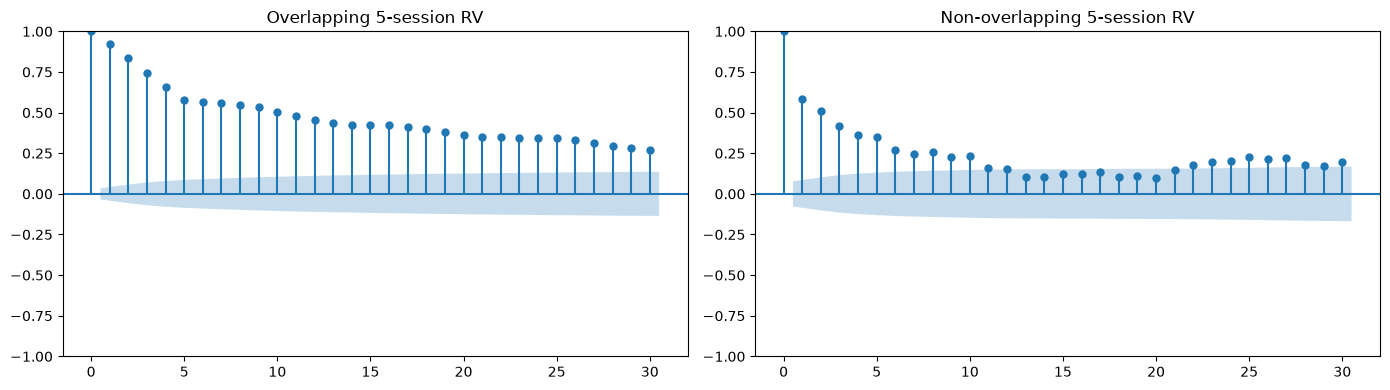

In [52]:
returns = df["daily_ret"].dropna()

squared_returns = returns.pow(2)

block_number = np.arange(len(squared_returns)) // 5

nonoverlap_rv_5 = np.sqrt(squared_returns.groupby(block_number).sum())

block_dates = returns.groupby(block_number).apply(lambda x: x.index[-1])

nonoverlap_rv_5.index = pd.DatetimeIndex(block_dates.values)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(df["rv_5"].dropna(),
    lags=30,
    ax=axes[0],
    alpha=0.05)

axes[0].set_title("Overlapping 5-session RV")

plot_acf(nonoverlap_rv_5,
    lags=30,
    ax=axes[1],
    alpha=0.05)

axes[1].set_title("Non-overlapping 5-session RV")

plt.tight_layout()
plt.show()

## Benchmarks

### Historical RV benchmark

In [78]:
df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime").reset_index(drop=True)

assert "target_rv_5" in df.columns, "target_rv_5 is missing."

linear_features = ["rv_5",
    "rv_10",
    "rv_20",
    "rv_60",
    "rv_ratio_5_20",
    "rv_20_std",
    "rv_5_change",
    "daily_abs",
    "squared_ret",
    "high_low_range",
    "overnight_gap",]


df["variance_daily"] = df["daily_ret"].pow(2)

df["har_daily"] = np.sqrt(df["variance_daily"])

df["har_weekly"] = np.sqrt(df["variance_daily"].rolling(5).mean())

df["har_monthly"] = np.sqrt(df["variance_daily"].rolling(22).mean())

har_features = ["har_daily","har_weekly","har_monthly",]

required_columns = list(dict.fromkeys(["Datetime", "target_rv_5", "rv_5"] + linear_features + har_features))

model_data = (df[required_columns].replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True))

if len(model_data) < 100:raise ValueError(f"Only {len(model_data)} complete observations. ""Check missing values and feature construction.")

print("Usable observations:", len(model_data))
print("First date:", model_data["Datetime"].min())
print("Last date:", model_data["Datetime"].max())

#split_position = int(len(model_data) * 0.80)

split = int(len(model_data) * 0.80)
purge = 5

train = model_data.iloc[:split - purge].copy()
test = model_data.iloc[split:].copy()

print("\nTraining observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train["Datetime"].max())
print("Testing starts:", test["Datetime"].min())

y_test = test["target_rv_5"].to_numpy()

pred_historical = test["rv_5"].to_numpy()

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,}


hist_rv_results = pd.DataFrame([evaluate_model("Historical RV",y_test,pred_historical)])

print("\nTEST-SET PERFORMANCE")
print(hist_rv_results.to_string(index=False,formatters={"MAE": "{:.6f}".format,"RMSE": "{:.6f}".format,"R2": "{:.4f}".format,}))


# forecast_results = pd.DataFrame({
#     "Datetime": test["Datetime"].to_numpy(),
#     "Actual_RV_5": y_test,
#     "Historical_RV_Forecast": pred_historical,
#     "Linear_Regression_Forecast": pred_linear,
#     "HAR_Forecast": pred_har,
# })

# forecast_results.to_csv(
#     "rv_5_benchmark_forecasts.csv",
#     index=False
# )

# print("\nForecasts saved to rv_5_benchmark_forecasts.csv")

Usable observations: 3099
First date: 2014-03-28 00:00:00
Last date: 2026-10-15 00:00:00

Training observations: 2474
Testing observations: 620
Training ends: 2024-04-08 00:00:00
Testing starts: 2024-04-18 00:00:00

TEST-SET PERFORMANCE
        Model      MAE     RMSE      R2
Historical RV 0.008639 0.013945 -0.3102


### Linear Regressin benchmark

In [79]:
X_train_linear = train[linear_features]
y_train = train["target_rv_5"]

X_test_linear = test[linear_features]

linear_model = LinearRegression()

linear_model.fit(X_train_linear, y_train)

pred_linear = linear_model.predict(X_test_linear)

lr_rv_results = pd.DataFrame([evaluate_model("Linear Regression",y_test,pred_linear)])

print("\nTEST-SET PERFORMANCE")
print(lr_rv_results.to_string(index=False,formatters={"MAE": "{:.6f}".format,"RMSE": "{:.6f}".format,"R2": "{:.4f}".format,}))


TEST-SET PERFORMANCE
            Model      MAE     RMSE     R2
Linear Regression 0.007854 0.011950 0.0379


### HAR-RV benchmark

In [80]:
X_train_har = train[har_features]
X_test_har = test[har_features]

har_model = LinearRegression()

har_model.fit(X_train_har, y_train)

pred_har = har_model.predict(X_test_har)

har_rv_results = pd.DataFrame([evaluate_model("HAR-style Regression",y_test,pred_har)])

print("\nTEST-SET PERFORMANCE")
print(har_rv_results.to_string(index=False,formatters={"MAE": "{:.6f}".format,"RMSE": "{:.6f}".format,"R2": "{:.4f}".format,}))

har_coefficients = pd.DataFrame({
    "Feature": har_features,
    "Coefficient": har_model.coef_,
})

print("\nHAR-STYLE MODEL COEFFICIENTS")
print(har_coefficients.to_string(index=False))

print("\nHAR-STYLE INTERCEPT:", har_model.intercept_)


TEST-SET PERFORMANCE
               Model      MAE     RMSE     R2
HAR-style Regression 0.007945 0.011757 0.0688

HAR-STYLE MODEL COEFFICIENTS
    Feature  Coefficient
  har_daily     0.037534
 har_weekly     0.677359
har_monthly     0.934199

HAR-STYLE INTERCEPT: 0.006307683487223256


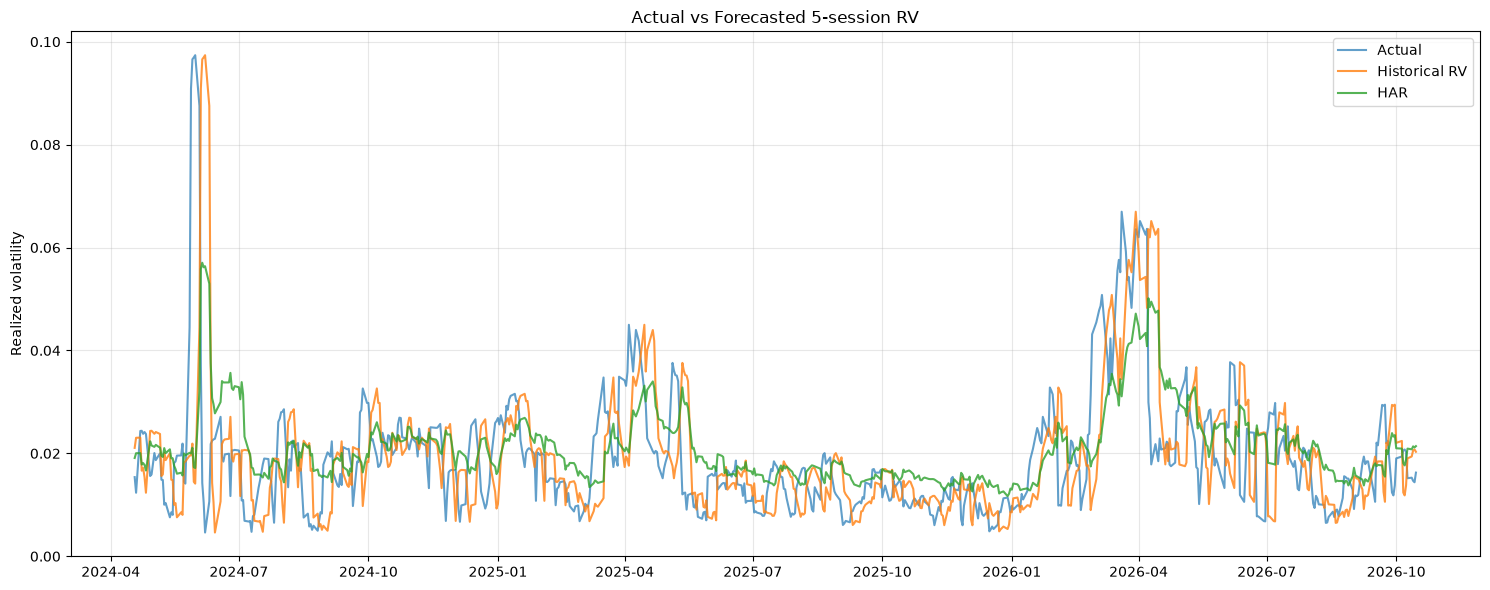


PERFORMANCE BY VOLATILITY REGIME
                   Observations  Actual mean RV  Historical MAE  Linear MAE  \
Regime                                                                        
Low volatility            207.0        0.009572        0.007511    0.008743   
Medium volatility         206.0        0.016889        0.006821    0.004758   
High volatility           207.0        0.031059        0.011577    0.010046   

                    HAR MAE  Historical RMSE  Linear RMSE  HAR RMSE  
Regime                                                               
Low volatility     0.008928         0.013464     0.011060  0.011007  
Medium volatility  0.004923         0.010362     0.006950  0.007080  
High volatility    0.009969         0.017156     0.016041  0.015587  

FORECAST BIAS
            Mean error  Underpredictions  Overpredictions
Historical     -0.0000            0.4871           0.5129
Linear         -0.0018            0.3355           0.6645
HAR            -0.0018         

In [82]:
forecast_results = pd.DataFrame({
    "Datetime": test["Datetime"].to_numpy(),
    "Actual": y_test,
    "Historical": pred_historical,
    "Linear": pred_linear,
    "HAR": pred_har,
})

forecast_results = forecast_results.set_index("Datetime")

# ------------------------------------------------
# 1. Actual vs predicted volatility
# ------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    forecast_results.index,
    forecast_results["Actual"],
    label="Actual",
    alpha=0.7
)

plt.plot(
    forecast_results.index,
    forecast_results["Historical"],
    label="Historical RV",
    alpha=0.8
)

plt.plot(
    forecast_results.index,
    forecast_results["HAR"],
    label="HAR",
    alpha=0.8
)

plt.title("Actual vs Forecasted 5-session RV")
plt.ylabel("Realized volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 2. Forecast errors
# ------------------------------------------------

for model in ["Historical", "Linear", "HAR"]:
    forecast_results[f"{model}_error"] = (
        forecast_results["Actual"] -
        forecast_results[model]
    )

    forecast_results[f"{model}_abs_error"] = (
        forecast_results[f"{model}_error"].abs()
    )


# ------------------------------------------------
# 3. Error performance by actual volatility regime
# ------------------------------------------------

# Define regimes using the test-set actual target distribution.
# These are diagnostic groups, not model inputs.

forecast_results["Regime"] = pd.qcut(
    forecast_results["Actual"],
    q=3,
    labels=["Low volatility", "Medium volatility", "High volatility"]
)

regime_results = (
    forecast_results
    .groupby("Regime", observed=True)
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),
            "Actual mean RV": group["Actual"].mean(),
            "Historical MAE": group["Historical_abs_error"].mean(),
            "Linear MAE": group["Linear_abs_error"].mean(),
            "HAR MAE": group["HAR_abs_error"].mean(),
            "Historical RMSE": np.sqrt(np.mean(group["Historical_error"] ** 2)),
            "Linear RMSE": np.sqrt(np.mean(group["Linear_error"] ** 2)),"HAR RMSE": np.sqrt(np.mean(group["HAR_error"] ** 2)),})))

print("\nPERFORMANCE BY VOLATILITY REGIME")
print(regime_results.round(6))


bias_results = pd.DataFrame({
    model: {
        "Mean error": forecast_results[f"{model}_error"].mean(),
        "Underpredictions": (
            forecast_results[f"{model}_error"] > 0
        ).mean(),
        "Overpredictions": (
            forecast_results[f"{model}_error"] < 0
        ).mean(),
    }
    for model in ["Historical", "Linear", "HAR"]
}).T

print("\nFORECAST BIAS")
print(bias_results.round(4))

In [84]:
# ============================================================
# CONDITIONAL FORECAST BIAS
# ============================================================

bias_by_regime = (forecast_results.groupby("Regime", observed=True).apply(lambda g: pd.Series({
            "Actual_RV": g["Actual"].mean(),
            "Historical_Forecast": g["Historical"].mean(),
            "Linear_Forecast": g["Linear"].mean(),
            "HAR_Forecast": g["HAR"].mean(),
            "Historical_Bias": g["Historical_error"].mean(),
            "Linear_Bias": g["Linear_error"].mean(),
            "HAR_Bias": g["HAR_error"].mean(),
            "Linear_Underprediction_%": (g["Linear_error"] > 0).mean() * 100,
            "HAR_Underprediction_%": (g["HAR_error"] > 0).mean() * 100,})))

print(bias_by_regime.round(6))

                   Actual_RV  Historical_Forecast  Linear_Forecast  \
Regime                                                               
Low volatility      0.009572             0.016076         0.018312   
Medium volatility   0.016889             0.018117         0.020511   
High volatility     0.031059             0.023455         0.024088   

                   HAR_Forecast  Historical_Bias  Linear_Bias  HAR_Bias  \
Regime                                                                    
Low volatility         0.018500        -0.006503    -0.008739 -0.008928   
Medium volatility      0.020468        -0.001228    -0.003622 -0.003579   
High volatility        0.023973         0.007604     0.006971  0.007086   

                   Linear_Underprediction_%  HAR_Underprediction_%  
Regime                                                              
Low volatility                     0.483092               0.000000  
Medium volatility                 24.271845              29.126214

In [85]:
extreme_errors = forecast_results.copy()

extreme_errors["HAR_abs_error"] = (
    extreme_errors["Actual"] -
    extreme_errors["HAR"]).abs()

extreme_errors["HAR_error"] = (
    extreme_errors["Actual"] -
    extreme_errors["HAR"])

extreme_errors = extreme_errors.sort_values(
    "HAR_abs_error",
    ascending=False)

print(extreme_errors[["Actual",
            "HAR",
            "HAR_error",
            "HAR_abs_error",
            "Linear",
            "Historical",]].head(15).round(5))

             Actual      HAR  HAR_error  HAR_abs_error   Linear  Historical
Datetime                                                                   
2024-05-31  0.09738  0.01716    0.08023        0.08023  0.01779     0.01412
2024-05-30  0.09696  0.01732    0.07963        0.07963  0.02137     0.01447
2024-05-29  0.09659  0.02109    0.07550        0.07550  0.01939     0.02190
2024-05-28  0.09088  0.01999    0.07090        0.07090  0.01655     0.01960
2024-06-03  0.08754  0.03207    0.05547        0.05547  0.01463     0.04450
2024-06-07  0.00462  0.05636   -0.05175        0.05175  0.05915     0.09738
2024-06-06  0.01049  0.05617   -0.04568        0.04568  0.05390     0.09696
2024-06-05  0.01426  0.05705   -0.04279        0.04279  0.06523     0.09659
2024-06-10  0.01067  0.05297   -0.04230        0.04230  0.05748     0.08754
2026-03-20  0.06697  0.03108    0.03588        0.03588  0.03437     0.03446
2026-04-10  0.01786  0.04949   -0.03163        0.03163  0.03898     0.06515
2026-04-15  

        Model  Calibration_intercept  Calibration_slope  Correlation
0  Historical                 0.0126             0.3448       0.3448
1      Linear                 0.0069             0.5846       0.3468
2         HAR                 0.0059             0.6336       0.3691


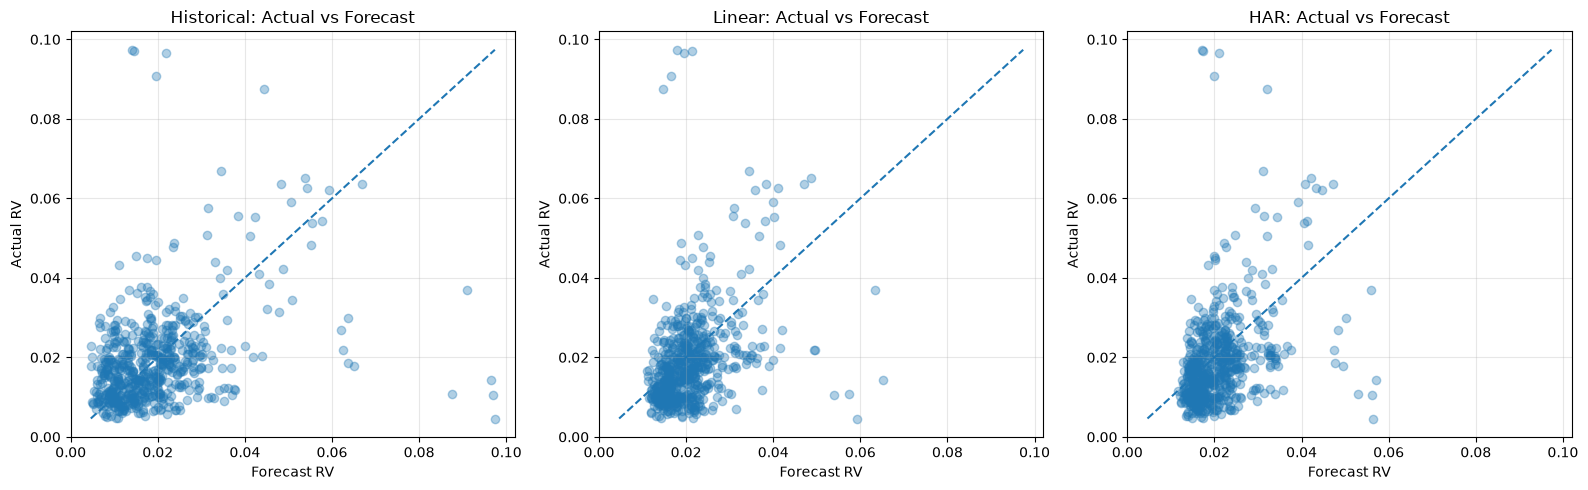

In [88]:
models = ["Historical", "Linear", "HAR"]

calibration_results = []

for model in models:

    actual = forecast_results["Actual"]
    predicted = forecast_results[model]

    slope, intercept = np.polyfit(predicted, actual, 1)

    correlation = actual.corr(predicted)

    calibration_results.append({
        "Model": model,
        "Calibration_intercept": intercept,
        "Calibration_slope": slope,
        "Correlation": correlation})

calibration_results = pd.DataFrame(calibration_results)

print(calibration_results.round(4))


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, model in zip(axes, models):

    actual = forecast_results["Actual"]
    predicted = forecast_results[model]

    ax.scatter(predicted, actual, alpha=0.35)

    limits = [min(actual.min(), predicted.min()),max(actual.max(), predicted.max())]

    ax.plot(limits, limits, linestyle="--")

    ax.set_title(f"{model}: Actual vs Forecast")
    ax.set_xlabel("Forecast RV")
    ax.set_ylabel("Actual RV")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [89]:
y = forecast_results["Actual"]

print("Target distribution:")
print(y.describe(percentiles=[
    0.50, 0.75, 0.90, 0.95, 0.99
]))

print("\nSkewness:", y.skew())
print("Kurtosis:", y.kurtosis())

print("\nForecast range:")
print(forecast_results[["Actual", "Historical", "Linear", "HAR"]].agg(["min", "max", "mean", "std"]))

Target distribution:
count    620.000000
mean       0.019177
std        0.012193
min        0.004619
50%        0.016978
75%        0.022898
90%        0.030139
95%        0.038483
99%        0.064862
max        0.097385
Name: Actual, dtype: float64

Skewness: 2.801368633850146
Kurtosis: 12.129814223204692

Forecast range:
        Actual  Historical    Linear       HAR
min   0.004619    0.004619  0.011120  0.011687
max   0.097385    0.097385  0.065228  0.057051
mean  0.019177    0.019218  0.020971  0.020981
std   0.012193    0.012190  0.007232  0.007104


In [90]:
forecast_results["Actual_decile"] = pd.qcut(
    forecast_results["Actual"],
    q=10,
    labels=False,
    duplicates="drop")

decile_errors = forecast_results.groupby(
    "Actual_decile",observed=True).apply(lambda x: pd.Series({"n": len(x),
        "actual_mean": x["Actual"].mean(),
        "HAR_forecast_mean": x["HAR"].mean(),
        "HAR_MAE": x["HAR_error"].abs().mean(),
        "HAR_bias": x["HAR_error"].mean()}))

print(decile_errors)

                  n  actual_mean  HAR_forecast_mean   HAR_MAE  HAR_bias
Actual_decile                                                          
0              62.0     0.007048           0.018288  0.011239 -0.011239
1              62.0     0.009411           0.017514  0.008103 -0.008103
2              62.0     0.011191           0.019396  0.008206 -0.008206
3              62.0     0.013461           0.019227  0.005848 -0.005766
4              62.0     0.015790           0.018437  0.003505 -0.002648
5              62.0     0.018012           0.021482  0.005624 -0.003470
6              62.0     0.020243           0.023305  0.005280 -0.003062
7              62.0     0.022965           0.022497  0.004852  0.000468
8              62.0     0.027308           0.021951  0.007423  0.005357
9              62.0     0.046345           0.027718  0.019370  0.018627


### Classification benchmark

In [93]:
df["future_return_5"] = sum(df["daily_ret"].shift(-i)for i in range(1, 6))

df["direction_5"] = np.where(df["future_return_5"] > 0, 1,np.where(df["future_return_5"] < 0, 0, np.nan))

In [94]:
feature_cols = [
    "rv_5",
    "rv_10",
    "rv_20",
    "rv_60",
    "rv_ratio_5_20",
    "rv_20_std",
    "rv_5_change",
    "daily_abs",
    "squared_ret",
    "high_low_range",
    "overnight_gap"]

target_cols = ["target_rv_5","direction_5"]

model_data = df[["Datetime"] + feature_cols + target_cols].dropna().copy()

print("Dataset shape:", model_data.shape)
print("Start:", model_data["Datetime"].min())
print("End:", model_data["Datetime"].max())

Dataset shape: (3099, 14)
Start: 2014-03-28
End: 2026-10-15


In [96]:
split_idx = int(len(model_data) * 0.80)

train = model_data.iloc[:split_idx - 5].copy()
test = model_data.iloc[split_idx:].copy()

# Calculate thresholds using training data ONLY
q25, q75, q90 = train["target_rv_5"].quantile([0.25, 0.75, 0.90])

print("Training volatility thresholds:")
print("25th percentile:", q25)
print("75th percentile:", q75)
print("90th percentile:", q90)

Training volatility thresholds:
25th percentile: 0.015839738945241863
75th percentile: 0.03190637485359681
90th percentile: 0.04451551644839339


In [97]:
bins = [-np.inf, q25, q75, q90, np.inf]

class_names = [
    "Very Low",
    "Normal",
    "High",
    "Extreme"]

train["vol_class"] = pd.cut(
    train["target_rv_5"],
    bins=bins,
    labels=range(4),
    include_lowest=True).astype(int)

test["vol_class"] = pd.cut(test["target_rv_5"],bins=bins,labels=range(4),include_lowest=True).astype(int)

In [98]:
print("TRAINING CLASS COUNTS")
print(train["vol_class"].value_counts().sort_index())

print("\nTRAINING CLASS PROPORTIONS")
print(train["vol_class"].value_counts(
    normalize=True
).sort_index())

print("\nTEST CLASS COUNTS")
print(test["vol_class"].value_counts().sort_index())

print("\nTEST CLASS PROPORTIONS")
print(test["vol_class"].value_counts(
    normalize=True
).sort_index())

TRAINING CLASS COUNTS
vol_class
0     619
1    1236
2     371
3     248
Name: count, dtype: int64

TRAINING CLASS PROPORTIONS
vol_class
0    0.250202
1    0.499596
2    0.149960
3    0.100243
Name: proportion, dtype: float64

TEST CLASS COUNTS
vol_class
0    279
1    288
2     29
3     24
Name: count, dtype: int64

TEST CLASS PROPORTIONS
vol_class
0    0.450000
1    0.464516
2    0.046774
3    0.038710
Name: proportion, dtype: float64


In [99]:
print(train.groupby("vol_class", observed=True)["target_rv_5"].agg(["count", "min", "mean", "median", "max"]))

           count       min      mean    median       max
vol_class                                               
0            619  0.003389  0.012045  0.012568  0.015837
1           1236  0.015847  0.022348  0.021408  0.031881
2            371  0.031915  0.037517  0.037062  0.044511
3            248  0.044517  0.065110  0.055317  0.199161


In [102]:
X_train = train[feature_cols]
X_test = test[feature_cols]

y_train_vol = train["vol_class"]
y_test_vol = test["vol_class"]

vol_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

vol_model.fit(X_train, y_train_vol)

vol_predictions = vol_model.predict(X_test)
vol_probabilities = vol_model.predict_proba(X_test)

In [104]:
print("Accuracy:",accuracy_score(y_test_vol, vol_predictions))

print("Balanced accuracy:",balanced_accuracy_score(y_test_vol, vol_predictions))

print("Macro F1:",f1_score(y_test_vol, vol_predictions, average="macro"))

print("\nClassification report:")
print(classification_report(
    y_test_vol,
    vol_predictions,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_test_vol,
    vol_predictions,
    labels=[0, 1, 2, 3]))

print("\nMulticlass log loss:",log_loss(y_test_vol, vol_probabilities, labels=[0, 1, 2, 3]))

Accuracy: 0.5790322580645161
Balanced accuracy: 0.31535618279569894
Macro F1: 0.3017693197426444

Classification report:
              precision    recall  f1-score   support

    Very Low       0.67      0.48      0.56       279
      Normal       0.55      0.78      0.65       288
        High       0.00      0.00      0.00        29
     Extreme       0.00      0.00      0.00        24

    accuracy                           0.58       620
   macro avg       0.31      0.32      0.30       620
weighted avg       0.56      0.58      0.55       620


Confusion matrix:
[[133 142   0   4]
 [ 58 226   4   0]
 [  5  23   0   1]
 [  2  17   5   0]]

Multiclass log loss: 0.9297154135483624


In [105]:
y_train_dir = train["direction_5"].astype(int)
y_test_dir = test["direction_5"].astype(int)

direction_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000,random_state=42))])

direction_model.fit(X_train, y_train_dir)

direction_predictions = direction_model.predict(X_test)
direction_probabilities = direction_model.predict_proba(X_test)

In [106]:
print("Direction accuracy:",
      accuracy_score(y_test_dir, direction_predictions))

print("Direction balanced accuracy:",
      balanced_accuracy_score(y_test_dir, direction_predictions))

print("\nDirection report:")
print(classification_report(
    y_test_dir,
    direction_predictions,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0))

print("\nDirection confusion matrix:")
print(confusion_matrix(
    y_test_dir,
    direction_predictions,
    labels=[0, 1]))

Direction accuracy: 0.5096774193548387
Direction balanced accuracy: 0.48513218732713365

Direction report:
              precision    recall  f1-score   support

        Down       0.33      0.04      0.07       293
          Up       0.52      0.93      0.67       327

    accuracy                           0.51       620
   macro avg       0.43      0.49      0.37       620
weighted avg       0.43      0.51      0.38       620


Direction confusion matrix:
[[ 11 282]
 [ 22 305]]


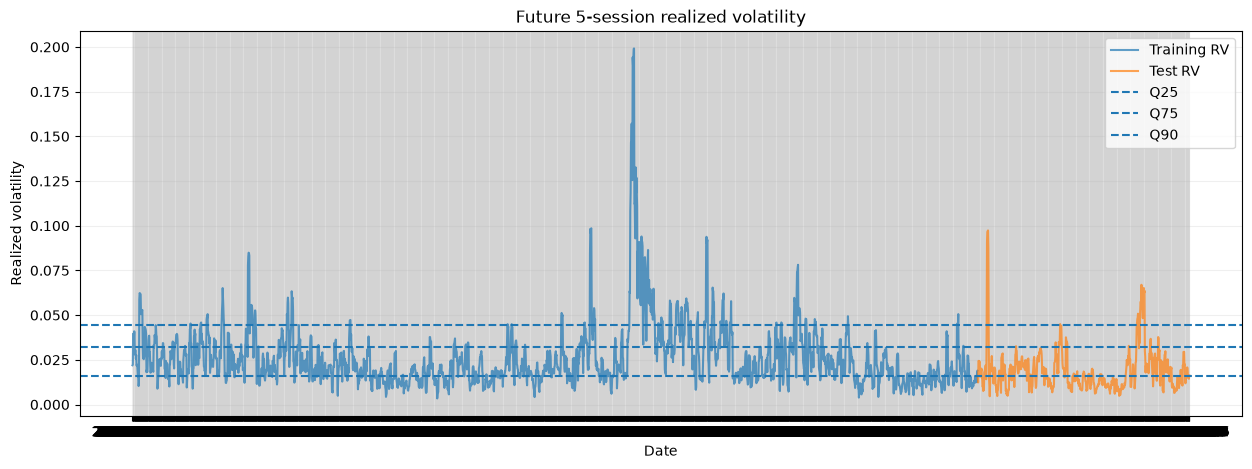

In [107]:
plt.figure(figsize=(15, 5))

plt.plot(
    train["Datetime"],
    train["target_rv_5"],
    label="Training RV",
    alpha=0.7)

plt.plot(
    test["Datetime"],
    test["target_rv_5"],
    label="Test RV",
    alpha=0.7)

plt.axhline(q25, linestyle="--", label="Q25")
plt.axhline(q75, linestyle="--", label="Q75")
plt.axhline(q90, linestyle="--", label="Q90")

plt.title("Future 5-session realized volatility")
plt.ylabel("Realized volatility")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [111]:
feature_shift = pd.DataFrame({
    "Train_Mean": train[feature_cols].mean(),
    "Test_Mean": test[feature_cols].mean(),
    "Train_Std": train[feature_cols].std(),
    "Test_Std": test[feature_cols].std()})

feature_shift["Mean_Difference"] = (feature_shift["Test_Mean"] - feature_shift["Train_Mean"])

feature_shift["Standardized_Difference"] = (feature_shift["Mean_Difference"] / train[feature_cols].std())

print(feature_shift.round(4))

                Train_Mean  Test_Mean  Train_Std  Test_Std  Mean_Difference  \
rv_5                0.0263     0.0192     0.0179    0.0122          -0.0071   
rv_10               0.0385     0.0282     0.0235    0.0154          -0.0103   
rv_20               0.0557     0.0410     0.0312    0.0196          -0.0148   
rv_60               0.0999     0.0743     0.0484    0.0260          -0.0256   
rv_ratio_5_20       0.4742     0.4775     0.1561    0.1698           0.0033   
rv_20_std           0.0089     0.0070     0.0064    0.0060          -0.0019   
rv_5_change        -0.0000     0.0000     0.0071    0.0055           0.0000   
daily_abs           0.0097     0.0071     0.0105    0.0073          -0.0026   
squared_ret         0.0002     0.0001     0.0008    0.0003          -0.0001   
high_low_range      0.0161     0.0118     0.0115    0.0066          -0.0043   
overnight_gap       0.0014     0.0004     0.0079    0.0063          -0.0010   

                Standardized_Difference  
rv_5     

In [112]:

dummy_vol = DummyClassifier(strategy="most_frequent")
dummy_vol.fit(X_train, y_train_vol)

dummy_vol_pred = dummy_vol.predict(X_test)

print("Volatility baseline")
print("Accuracy:", accuracy_score(y_test_vol, dummy_vol_pred))
print("Balanced accuracy:",
      balanced_accuracy_score(y_test_vol, dummy_vol_pred))
print("Macro F1:",
      f1_score(y_test_vol, dummy_vol_pred, average="macro"))


# Direction benchmark
dummy_dir = DummyClassifier(strategy="most_frequent")
dummy_dir.fit(X_train, y_train_dir)

dummy_dir_pred = dummy_dir.predict(X_test)

print("\nDirection baseline")
print("Accuracy:", accuracy_score(y_test_dir, dummy_dir_pred))
print("Balanced accuracy:",
      balanced_accuracy_score(y_test_dir, dummy_dir_pred))

Volatility baseline
Accuracy: 0.4645161290322581
Balanced accuracy: 0.25
Macro F1: 0.15859030837004406

Direction baseline
Accuracy: 0.5274193548387097
Balanced accuracy: 0.5


#### Walk forward testing

In [118]:
tscv = TimeSeriesSplit(n_splits=5,gap=5)
vol_results = []
direction_results = []

vol_confusion = []
direction_confusion = []

fold_thresholds = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(model_data), start=1):

    fold_train = model_data.iloc[train_idx].copy()
    fold_val = model_data.iloc[val_idx].copy()

    q25, q75, q90 = fold_train[
        "target_rv_5"
    ].quantile([0.25, 0.75, 0.90])

    if not q25 < q75 < q90:
        raise ValueError(
            f"Invalid thresholds in fold {fold}")

    bins = [-np.inf, q25, q75, q90, np.inf]

    fold_train["vol_class"] = pd.cut(
        fold_train["target_rv_5"],
        bins=bins,
        labels=[0, 1, 2, 3],
        include_lowest=True).astype(int)

    fold_val["vol_class"] = pd.cut(
        fold_val["target_rv_5"],
        bins=bins,
        labels=[0, 1, 2, 3],
        include_lowest=True).astype(int)

    fold_thresholds.append({
        "Fold": fold,
        "Q25": q25,
        "Q75": q75,
        "Q90": q90})

    X_train = fold_train[feature_cols]
    X_val = fold_val[feature_cols]

    y_train_vol = fold_train["vol_class"]
    y_val_vol = fold_val["vol_class"]

    y_train_dir = fold_train["direction_5"].astype(int)
    y_val_dir = fold_val["direction_5"].astype(int)

    vol_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000,random_state=42))])

    vol_model.fit(X_train, y_train_vol)

    vol_pred = vol_model.predict(X_val)
    vol_prob = vol_model.predict_proba(X_val)

    vol_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val_vol, vol_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_val_vol, vol_pred),
        "Macro_F1": f1_score(y_val_vol, vol_pred, average="macro"),
        "Log_Loss": log_loss(y_val_vol,vol_prob,labels=[0, 1, 2, 3]),
        "Extreme_Recall": classification_report(
            y_val_vol,
            vol_pred,
            labels=[0, 1, 2, 3],
            output_dict=True,
            zero_division=0
        )["3"]["recall"]})

    vol_confusion.append(
        confusion_matrix(
            y_val_vol,
            vol_pred,
            labels=[0, 1, 2, 3]))

    direction_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    direction_model.fit(X_train, y_train_dir)

    direction_pred = direction_model.predict(X_val)
    direction_prob = direction_model.predict_proba(X_val)

    direction_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(
            y_val_dir, direction_pred),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_val_dir, direction_pred),
        "Macro_F1": f1_score(
            y_val_dir, direction_pred, average="macro"),
        "Log_Loss": log_loss(
            y_val_dir,
            direction_prob,
            labels=[0, 1])})

    direction_confusion.append(
        confusion_matrix(
            y_val_dir,
            direction_pred,
            labels=[0, 1]))


vol_results = pd.DataFrame(vol_results)
direction_results = pd.DataFrame(direction_results)
fold_thresholds = pd.DataFrame(fold_thresholds)

print("VOLATILITY CLASSIFICATION")
print(vol_results.round(4))

print("\nDIRECTION CLASSIFICATION")
print(direction_results.round(4))

print("\nFOLD-SPECIFIC VOLATILITY THRESHOLDS")
print(fold_thresholds.round(5))

VOLATILITY CLASSIFICATION
   Fold  Accuracy  Balanced_Accuracy  Macro_F1  Log_Loss  Extreme_Recall
0     1    0.2519             0.2828    0.1348    1.8996          0.0000
1     2    0.4748             0.3398    0.3409    1.1599          0.4132
2     3    0.4070             0.2750    0.2089    1.3069          0.1212
3     4    0.4806             0.2744    0.2462    0.9737          0.0000
4     5    0.5833             0.3204    0.3048    0.8950          0.0000

DIRECTION CLASSIFICATION
   Fold  Accuracy  Balanced_Accuracy  Macro_F1  Log_Loss
0     1    0.4554             0.4939    0.4547    0.7297
1     2    0.5291             0.5104    0.4256    0.7263
2     3    0.5368             0.4936    0.3872    0.6974
3     4    0.5814             0.5091    0.4683    0.6858
4     5    0.5000             0.5000    0.3333    0.7062

FOLD-SPECIFIC VOLATILITY THRESHOLDS
   Fold      Q25      Q75      Q90
0     1  0.01994  0.03526  0.04450
1     2  0.01597  0.02979  0.03897
2     3  0.01621  0.03105 

In [122]:
class_distribution = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(model_data), start=1):

    fold_train = model_data.iloc[train_idx]
    fold_val = model_data.iloc[val_idx]

    q25, q75, q90 = fold_train["target_rv_5"].quantile([0.25, 0.75, 0.90])

    bins = [-np.inf, q25, q75, q90, np.inf]

    train_classes = pd.cut(
        fold_train["target_rv_5"],
        bins=bins,
        labels=[0, 1, 2, 3],
        include_lowest=True)

    val_classes = pd.cut(
        fold_val["target_rv_5"],
        bins=bins,
        labels=[0, 1, 2, 3],
        include_lowest=True)

    for dataset_name, classes in [("Train", train_classes),("Validation", val_classes)]:

        counts = classes.value_counts().sort_index()

        for class_id in range(4):
            class_distribution.append({
                "Fold": fold,
                "Dataset": dataset_name,
                "Class": class_id,
                "Count": counts.get(class_id, 0),
                "Proportion": (counts.get(class_id, 0) / len(classes))})

class_distribution = pd.DataFrame(class_distribution)

print(class_distribution.round(4))

    Fold     Dataset  Class  Count  Proportion
0      1       Train      0    129      0.2510
1      1       Train      1    256      0.4981
2      1       Train      2     77      0.1498
3      1       Train      3     52      0.1012
4      1  Validation      0    325      0.6298
5      1  Validation      1    171      0.3314
6      1  Validation      2     17      0.0329
7      1  Validation      3      3      0.0058
8      2       Train      0    258      0.2505
9      2       Train      1    514      0.4990
10     2       Train      2    155      0.1505
11     2       Train      3    103      0.1000
12     2  Validation      0     99      0.1919
13     2  Validation      1    241      0.4671
14     2  Validation      2     55      0.1066
15     2  Validation      3    121      0.2345
16     3       Train      0    387      0.2503
17     3       Train      1    772      0.4994
18     3       Train      2    232      0.1501
19     3       Train      3    155      0.1003
20     3  Val

In [120]:
for fold, cm in enumerate(vol_confusion, start=1):

    print(f"\nVOLATILITY CONFUSION MATRIX - FOLD {fold}")

    print(pd.DataFrame(
        cm,
        index=["Actual VL", "Actual Normal", "Actual High", "Actual Extreme"],
        columns=["Pred VL", "Pred Normal", "Pred High", "Pred Extreme"]))


VOLATILITY CONFUSION MATRIX - FOLD 1
                Pred VL  Pred Normal  Pred High  Pred Extreme
Actual VL             0          240         85             0
Actual Normal         0          123         48             0
Actual High           0           10          7             0
Actual Extreme        0            2          1             0

VOLATILITY CONFUSION MATRIX - FOLD 2
                Pred VL  Pred Normal  Pred High  Pred Extreme
Actual VL            23           76          0             0
Actual Normal        57          172          2            10
Actual High           3           48          0             4
Actual Extreme        5           59          7            50

VOLATILITY CONFUSION MATRIX - FOLD 3
                Pred VL  Pred Normal  Pred High  Pred Extreme
Actual VL             0           80          1             2
Actual Normal         0          192          9             5
Actual High           0           95          6            27
Actual Extreme    

In [121]:
for fold, cm in enumerate(direction_confusion, start=1):
    print(f"\nDIRECTION CONFUSION MATRIX - FOLD {fold}")
    print(pd.DataFrame(cm,index=["Actual Down", "Actual Up"],columns=["Pred Down", "Pred Up"]))


DIRECTION CONFUSION MATRIX - FOLD 1
             Pred Down  Pred Up
Actual Down        127       68
Actual Up          213      108

DIRECTION CONFUSION MATRIX - FOLD 2
             Pred Down  Pred Up
Actual Down         27      219
Actual Up           24      246

DIRECTION CONFUSION MATRIX - FOLD 3
             Pred Down  Pred Up
Actual Down         11      222
Actual Up           17      266

DIRECTION CONFUSION MATRIX - FOLD 4
             Pred Down  Pred Up
Actual Down         31      175
Actual Up           41      269

DIRECTION CONFUSION MATRIX - FOLD 5
             Pred Down  Pred Up
Actual Down          0      258
Actual Up            0      258


In [127]:
baseline_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(model_data), 1):

    train = model_data.iloc[train_idx]
    val = model_data.iloc[val_idx]

    X_train = train[feature_cols]
    X_val = val[feature_cols]

    # Recalculate volatility thresholds using training data only
    q25, q75, q90 = train["target_rv_5"].quantile([0.25, 0.75, 0.90])

    bins = [-np.inf, q25, q75, q90, np.inf]

    y_train_vol = pd.cut(train["target_rv_5"], bins=bins, labels=False)
    y_val_vol = pd.cut(val["target_rv_5"], bins=bins, labels=False)

    # Volatility classifiers
    for strategy in ["most_frequent", "stratified"]:

        dummy = DummyClassifier(strategy=strategy, random_state=42)
        dummy.fit(X_train, y_train_vol)
        pred = dummy.predict(X_val)
        prob = dummy.predict_proba(X_val)

        baseline_results.append({
            "Fold": fold,
            "Target": "Volatility",
            "Model": strategy,
            "Accuracy": accuracy_score(y_val_vol, pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_val_vol, pred),
            "Macro_F1": f1_score(y_val_vol, pred, average="macro"),
            "Log_Loss": log_loss(
                y_val_vol, prob, labels=dummy.classes_)})

    # Direction classifiers
    y_train_dir = train["direction_5"].astype(int)
    y_val_dir = val["direction_5"].astype(int)

    for strategy in ["most_frequent", "stratified"]:

        dummy = DummyClassifier(strategy=strategy, random_state=42)
        dummy.fit(X_train, y_train_dir)
        pred = dummy.predict(X_val)
        prob = dummy.predict_proba(X_val)

        baseline_results.append({
            "Fold": fold,
            "Target": "Direction",
            "Model": strategy,
            "Accuracy": accuracy_score(y_val_dir, pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_val_dir, pred),
            "Macro_F1": f1_score(y_val_dir, pred, average="macro"),
            "Log_Loss": log_loss(y_val_dir, prob, labels=dummy.classes_)})

baseline_df = pd.DataFrame(baseline_results)

print(baseline_df.round(4).to_string(index=False))

 Fold     Target         Model  Accuracy  Balanced_Accuracy  Macro_F1  Log_Loss
    1 Volatility most_frequent    0.3314             0.2500    0.1245   24.0990
    1 Volatility    stratified    0.3178             0.2150    0.1944   24.5879
    1  Direction most_frequent    0.6221             0.5000    0.3835   13.6211
    1  Direction    stratified    0.4535             0.4380    0.4371   19.6983
    2 Volatility most_frequent    0.4671             0.2500    0.1592   19.2093
    2 Volatility    stratified    0.3159             0.2505    0.2366   24.6578
    2  Direction most_frequent    0.5233             0.5000    0.3435   17.1836
    2  Direction    stratified    0.5039             0.5005    0.4992   17.8821
    3 Volatility most_frequent    0.3992             0.2500    0.1427   21.6541
    3 Volatility    stratified    0.3275             0.2818    0.2750   24.2387
    3  Direction most_frequent    0.5484             0.5000    0.3542   16.2755
    3  Direction    stratified    0.4942

### Target Transformation Approach

TARGET DISTRIBUTION
        Original_RV   Log_RV
mean        0.02489 -3.85729
std         0.01718  0.55453
min         0.00339 -5.68708
median      0.02023 -3.90060
max         0.19916 -1.61364

SKEWNESS
Original: 3.5127116823867817
Log: 0.28198178714291794

EXCESS KURTOSIS
Original: 22.35272414654023
Log: 0.5077683833162183


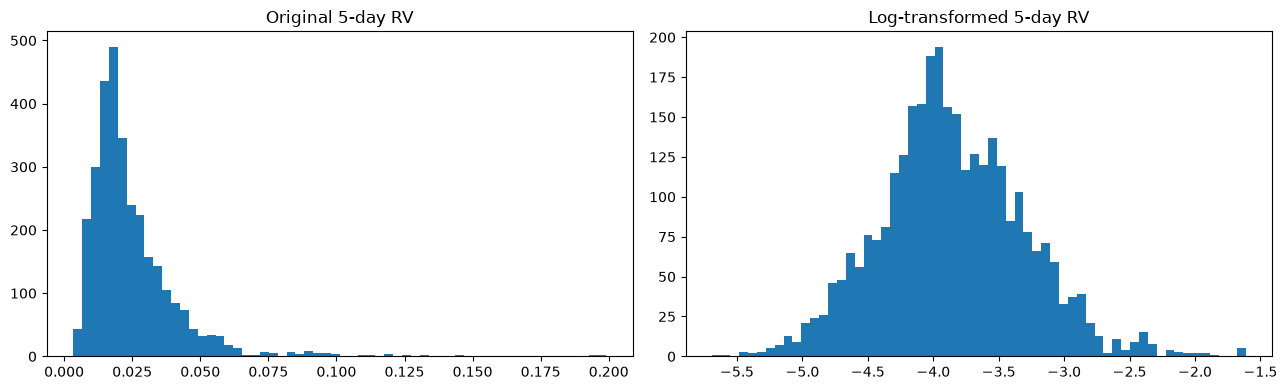

In [130]:
from scipy.stats import skew, kurtosis

rv = model_data["target_rv_5"]

target_diagnostics = pd.DataFrame({
    "Original_RV": rv,
    "Log_RV": np.log(rv)
})

print("TARGET DISTRIBUTION")
print(
    target_diagnostics.agg(
        ["mean", "std", "min", "median", "max"]
    ).round(5)
)

print("\nSKEWNESS")
print("Original:", skew(rv))
print("Log:", skew(np.log(rv)))

print("\nEXCESS KURTOSIS")
print("Original:", kurtosis(rv))
print("Log:", kurtosis(np.log(rv)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(rv, bins=60)
axes[0].set_title("Original 5-day RV")

axes[1].hist(np.log(rv), bins=60)
axes[1].set_title("Log-transformed 5-day RV")

plt.tight_layout()
plt.show()

In [131]:
regime_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(model_data), 1):

    train = model_data.iloc[train_idx]
    val = model_data.iloc[val_idx]

    for target_name, target_train, target_val in [
        ("Original",train["target_rv_5"],val["target_rv_5"]),
        ("Log",np.log(train["target_rv_5"]),np.log(val["target_rv_5"]))]:

        q25, q75, q90 = target_train.quantile([0.25, 0.75, 0.90])

        bins = [-np.inf, q25, q75, q90, np.inf]

        train_classes = pd.cut(target_train, bins=bins, labels=False)

        val_classes = pd.cut(target_val, bins=bins, labels=False)

        for dataset_name, classes in [
            ("Train", train_classes),
            ("Validation", val_classes)]:

            proportions = (
                classes.value_counts(normalize=True)
                .reindex([0, 1, 2, 3], fill_value=0))

            regime_results.append({
                "Fold": fold,
                "Target": target_name,
                "Dataset": dataset_name,
                "Very_Low": proportions[0],
                "Normal": proportions[1],
                "High": proportions[2],
                "Extreme": proportions[3]})

regime_comparison = pd.DataFrame(regime_results)

print(regime_comparison.round(3).to_string(index=False))

 Fold   Target    Dataset  Very_Low  Normal  High  Extreme
    1 Original      Train     0.251   0.498 0.150    0.101
    1 Original Validation     0.630   0.331 0.033    0.006
    1      Log      Train     0.251   0.498 0.150    0.101
    1      Log Validation     0.630   0.331 0.033    0.006
    2 Original      Train     0.250   0.499 0.150    0.100
    2 Original Validation     0.192   0.467 0.107    0.234
    2      Log      Train     0.250   0.499 0.150    0.100
    2      Log Validation     0.192   0.467 0.107    0.234
    3 Original      Train     0.250   0.499 0.150    0.100
    3 Original Validation     0.161   0.399 0.248    0.192
    3      Log      Train     0.250   0.499 0.150    0.100
    3      Log Validation     0.161   0.399 0.248    0.192
    4 Original      Train     0.250   0.500 0.150    0.100
    4 Original Validation     0.527   0.401 0.058    0.014
    4      Log      Train     0.250   0.500 0.150    0.100
    4      Log Validation     0.527   0.401 0.058    0.0

In [133]:
forecast_data = model_data.copy()

forecast_data["log_target_rv_5"] = np.log(forecast_data["target_rv_5"])

print(forecast_data[["target_rv_5", "log_target_rv_5"]].describe().round(4))

       target_rv_5  log_target_rv_5
count    3099.0000        3099.0000
mean        0.0249          -3.8573
std         0.0172           0.5545
min         0.0034          -5.6871
25%         0.0149          -4.2093
50%         0.0202          -3.9006
75%         0.0299          -3.5090
max         0.1992          -1.6136


In [135]:
forecast_results = []
forecast_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(forecast_data), 1):

    train = forecast_data.iloc[train_idx]
    val = forecast_data.iloc[val_idx]

    X_train = train[feature_cols]
    X_val = val[feature_cols]

    y_train = train["log_target_rv_5"]
    y_val = val["log_target_rv_5"]

    # 1. Historical RV benchmark
    pred_historical = np.log(val["rv_5"].clip(lower=1e-10))

    # 2. Multivariable linear regression
    linear_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())])

    linear_model.fit(X_train, y_train)
    pred_linear = linear_model.predict(X_val)

    # 3. HAR-style regression
    har_features = [
        "har_daily",
        "har_weekly",
        "har_monthly"]

    har_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())])

    har_model.fit(
        train[har_features],
        y_train)

    pred_har = har_model.predict(
        val[har_features])

    predictions = {
        "Historical": pred_historical,
        "Linear": pred_linear,
        "HAR": pred_har}

    for model_name, pred in predictions.items():

        forecast_results.append({
            "Fold": fold,
            "Model": model_name,
            "MAE_Log": mean_absolute_error(y_val, pred),
            "RMSE_Log": np.sqrt(mean_squared_error(y_val, pred)),
            "R2_Log": r2_score(y_val, pred)})

        # Convert predictions back to original RV scale
        actual_rv = np.exp(y_val)
        predicted_rv = np.exp(pred)

        forecast_predictions.append(
            pd.DataFrame({
                "Fold": fold,
                "Model": model_name,
                "Actual_Log_RV": y_val.values,
                "Predicted_Log_RV": pred,
                "Actual_RV": actual_rv.values,
                "Predicted_RV": predicted_rv
            }, index=val.index))

forecast_results_df = pd.DataFrame(forecast_results)

forecast_predictions_df = pd.concat(forecast_predictions).reset_index(drop=True)

print(forecast_results_df.round(4).to_string(index=False))

KeyError: "None of [Index(['har_daily', 'har_weekly', 'har_monthly'], dtype='str')] are in the [columns]"

In [136]:
original_scale_results = []

for (fold, model_name), group in forecast_predictions_df.groupby(["Fold", "Model"]):

    original_scale_results.append({
        "Fold": fold,
        "Model": model_name,
        "MAE_RV": mean_absolute_error(
            group["Actual_RV"],
            group["Predicted_RV"]),
        "RMSE_RV": np.sqrt(mean_squared_error(
            group["Actual_RV"],
            group["Predicted_RV"])),
        "Mean_Actual_RV": group["Actual_RV"].mean(),
        "Mean_Predicted_RV": group["Predicted_RV"].mean()})

original_scale_results_df = pd.DataFrame(original_scale_results)

print(original_scale_results_df.round(5).to_string(index=False))

NameError: name 'forecast_predictions_df' is not defined